### Display pair plots for correlated features by manually computing correlation coefficients, selecting highly correlated pairs dynamically, and plotting scatter plots with trendlines using low-level plotting functions.	

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
numerical = []

for column in df.columns:
    if df[column].dtype != "object":
        numerical.append(column)

print(numerical)

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [4]:
def correlation(x, y):
    
    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)

    top = 0
    bottom_x = 0
    bottom_y = 0

    for i in range(len(x)):
        top += (x[i] - mean_x) * (y[i] - mean_y)
        bottom_x += (x[i] - mean_x) ** 2
        bottom_y += (y[i] - mean_y) ** 2

    return top / (bottom_x * bottom_y) ** 0.5

In [5]:
pairs = []

for i in range(len(numerical)):
    for j in range(i + 1, len(numerical)):
        
        x = df[numerical[i]].tolist()
        y = df[numerical[j]].tolist()
        
        r = correlation(x, y)
        
        if abs(r) >= 0.5:
            pairs.append((numerical[i], numerical[j], r))

print(pairs)

[('oldpeak', 'slope', -0.577536816729141)]


In [6]:
for pair in pairs:
    print(pair[0], "vs", pair[1], "=", round(pair[2], 2))

oldpeak vs slope = -0.58


In [7]:
x_name = pairs[0][0]
y_name = pairs[0][1]

x = df[x_name].tolist()
y = df[y_name].tolist()

In [8]:
mean_x = sum(x) / len(x)
mean_y = sum(y) / len(y)

top = 0
bottom = 0

for i in range(len(x)):
    top += (x[i] - mean_x) * (y[i] - mean_y)
    bottom += (x[i] - mean_x) ** 2

slope = top / bottom
intercept = mean_y - slope * mean_x

print("Slope:", slope)
print("Intercept:", intercept)

Slope: -0.30652049144446986
Intercept: 1.7179998508416108


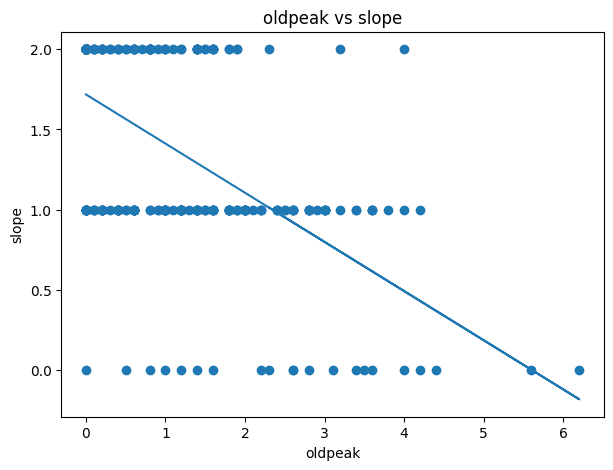

In [9]:
line_y = []

for value in x:
    line_y.append(slope * value + intercept)

plt.figure(figsize=(7, 5))

plt.scatter(x, y)
plt.plot(x, line_y)

plt.xlabel(x_name)
plt.ylabel(y_name)
plt.title(x_name + " vs " + y_name)

plt.show()

oldpeak vs slope


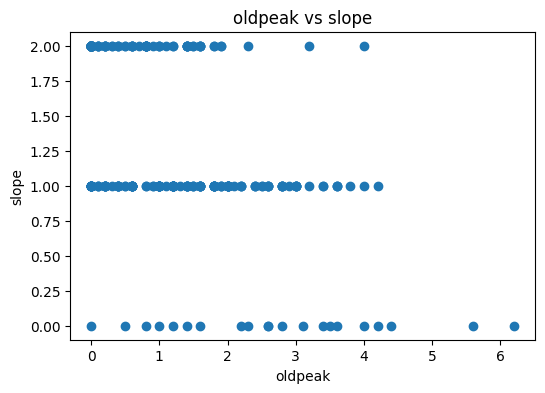

In [10]:
for pair in pairs:
    
    x_name = pair[0]
    y_name = pair[1]
    
    x = df[x_name].tolist()
    y = df[y_name].tolist()
    
    print(x_name, "vs", y_name)
    
    plt.figure(figsize=(6, 4))
    plt.scatter(x, y)
    
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(x_name + " vs " + y_name)
    
    plt.show()

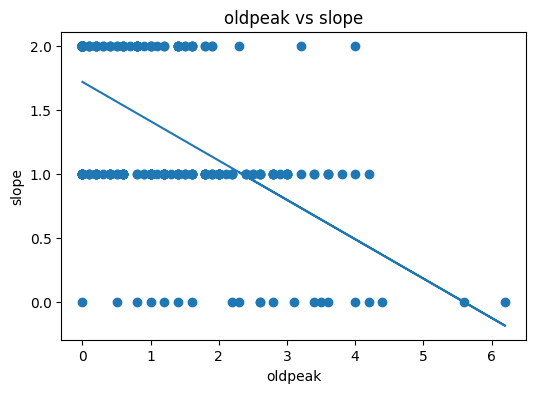

In [11]:
for pair in pairs:
    
    x_name = pair[0]
    y_name = pair[1]
    
    x = df[x_name].tolist()
    y = df[y_name].tolist()
    
    mean_x = sum(x) / len(x)
    mean_y = sum(y) / len(y)
    
    top = 0
    bottom = 0
    
    for i in range(len(x)):
        top += (x[i] - mean_x) * (y[i] - mean_y)
        bottom += (x[i] - mean_x) ** 2
    
    slope = top / bottom
    intercept = mean_y - slope * mean_x
    
    line_y = []
    
    for value in x:
        line_y.append(slope * value + intercept)
    
    plt.figure(figsize=(6, 4))
    plt.scatter(x, y)
    plt.plot(x, line_y)
    
    plt.xlabel(x_name)
    plt.ylabel(y_name)
    plt.title(x_name + " vs " + y_name)
    
    plt.show()

In [12]:
print("Highly correlated pairs:")

for pair in pairs:
    print(pair[0], "and", pair[1], "Correlation =", round(pair[2], 2))

Highly correlated pairs:
oldpeak and slope Correlation = -0.58
